# DataWizards · Guía 4 — Calidad, limpieza e integración municipal
**Proyecto:** Priorización de municipios colombianos para estudios de prefactibilidad de infraestructura pública de carga rápida de vehículos eléctricos.  
**Alcance:** Preparación, diagnóstico y comprensión de los datos; **no** predicción de rentabilidad ni ranking definitivo.

**Entradas esperadas:** archivos ya organizados en `data/raw/`, `reports/tables/eda_acc/` y `data/processed/` del repositorio.  
**Salidas:** `data/processed/dane/`, `data/processed/integracion/`, `data/processed/cargame/`, `reports/tables/guia4/` y `reports/figures/`.

> Ejecutar desde la raíz `E:/MIAD/DATAWIZARDS_Proyecto`, con `conda activate datawizards` y Jupyter. El notebook detecta la raíz incluso si Jupyter inicia dentro de `notebooks/`. No modifica las fuentes originales.

In [1]:
from pathlib import Path
import json
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = Path.cwd()
if not (ROOT / "data").exists() and (ROOT.parent / "data").exists():
    ROOT = ROOT.parent
assert (ROOT / "data").exists(), "Abra Jupyter desde la raíz del repositorio DataWizards."

RAW = ROOT / "data" / "raw"
PROCESSED = ROOT / "data" / "processed"
TABLES = ROOT / "reports" / "tables" / "guia4"
FIGURES = ROOT / "reports" / "figures"
for path in [PROCESSED / "dane", PROCESSED / "integracion", PROCESSED / "cargame", TABLES, FIGURES]:
    path.mkdir(parents=True, exist_ok=True)

print("Proyecto:", ROOT)
print("Pandas:", pd.__version__)


Proyecto: E:\MIAD\DATAWIZARDS_Proyecto
Pandas: 3.1.0


## 1. Validación de versiones del EDA de Erika
Se comprueban unicidad de DIVIPOLA, cobertura y coincidencia de las 12 variables comunes. `EDA_ACC` es la base candidata, pero no se asume que un municipio sin BEV sea un dato faltante.

In [2]:
ruta_eda = PROCESSED / "integracion" / "indicadores_por_municipio.csv"
ruta_acc = ROOT / "reports" / "tables" / "eda_acc" / "indicadores_por_municipio.csv"
assert ruta_eda.exists() and ruta_acc.exists(), "Faltan indicadores de EDA o EDA_ACC."
eda = pd.read_csv(ruta_eda, dtype={"divipola": "string"})
acc = pd.read_csv(ruta_acc, dtype={"divipola": "string"})
for frame in [eda, acc]:
    frame["divipola"] = frame["divipola"].astype("string").str.strip().str.zfill(5)

assert eda.divipola.is_unique and acc.divipola.is_unique, "Hay DIVIPOLA duplicados: revisar antes de unir."
assert set(eda.divipola) == set(acc.divipola), "Los EDA no cubren exactamente los mismos municipios."
x, y = eda.set_index("divipola").sort_index(), acc.set_index("divipola").sort_index()
comparacion = []
for campo in x.columns:
    coincide = x[campo].eq(y[campo]) | (x[campo].isna() & y[campo].isna())
    comparacion.append({"variable": campo, "diferencias": int((~coincide).sum())})
comparacion = pd.DataFrame(comparacion)
comparacion.to_csv(TABLES / "comparacion_eda_eda_acc.csv", index=False, encoding="utf-8-sig")
display(comparacion)
assert comparacion.diferencias.sum() == 0, "Las columnas comunes no coinciden; no integrar hasta revisar."
print(f"EDA_ACC validado: {len(acc):,} municipios, {len(acc.columns)} variables; 0 diferencias en variables comunes.")


,variable,diferencias
0,departamento,0
1,municipio,0
2,poblacion,0
3,bev_acum,0
4,sin_bev,0
5,matr_anio,0
6,crec_anual,0
7,bev_por_100k,0
8,matr_anio_por_100k,0
9,parque_liviano,0


EDA_ACC validado: 1,123 municipios, 17 variables; 0 diferencias en variables comunes.


## 2. Perfilamiento y limpieza de valor agregado DANE 2024p
Se lee **`Cuadro 15`**, cuyo encabezado está en la fila 11 de Excel (`header=10`), se excluyen notas y filas administrativas mediante códigos de **exactamente cinco dígitos**, se eliminan dos columnas vacías y se convierten variables cuantitativas. La unidad original es **miles de millones de COP corrientes**. No se imputa valor agregado de territorios sin dato.

In [3]:
archivo_dane = RAW / "dane_divipola" / "anex-PIBDep-ValorAgreMuni-2011-2024p.xlsx"
assert archivo_dane.exists(), f"No existe {archivo_dane}"
original = pd.read_excel(archivo_dane, sheet_name="Cuadro 15", header=10,
                         dtype={"Código Municipio": "string"})
original.columns = original.columns.astype(str).str.strip()

codigos = original["Código Municipio"].astype("string").str.strip()
valido = codigos.str.fullmatch(r"[0-9]{5}", na=False)
filas_descartadas = original.loc[~valido, ["Código Municipio"]].copy()
filas_descartadas["motivo"] = "Fila sin DIVIPOLA municipal de 5 dígitos (nota, fuente o espacio en blanco)"
filas_descartadas.to_csv(TABLES / "dane_filas_excluidas.csv", index=False, encoding="utf-8-sig")

columnas = {
    "Código Municipio": "divipola", "Municipio": "municipio_dane",
    "Código Departamento": "codigo_departamento_dane", "Departamento": "departamento_dane",
    "Actividades primarias *": "va_primarias_2024_mm_cop",
    "Actividades secundarias **": "va_secundarias_2024_mm_cop",
    "Actividades terciarias ***": "va_terciarias_2024_mm_cop",
    "Valor agregado": "va_total_2024_mm_cop",
    "Peso relativo municipal en el valor agregado departamental (%)": "peso_va_departamental_pct_2024"
}
dane = original.loc[valido].rename(columns=columnas)[list(columnas.values())].copy()
dane["divipola"] = dane["divipola"].astype("string").str.strip().str.zfill(5)
for c in [c for c in dane if c.endswith("_2024_mm_cop") or c.endswith("_pct_2024")]:
    dane[c] = pd.to_numeric(dane[c], errors="coerce")

assert dane.divipola.is_unique, "DANE presenta códigos repetidos."
assert dane.divipola.str.fullmatch(r"[0-9]{5}").all(), "DIVIPOLA DANE inválido."
for c in ["va_primarias_2024_mm_cop","va_secundarias_2024_mm_cop","va_terciarias_2024_mm_cop","va_total_2024_mm_cop"]:
    if (dane[c].dropna() < 0).any():
        print("ADVERTENCIA: hay cifras negativas en", c)

dane["va_suma_componentes_2024_mm_cop"] = dane[["va_primarias_2024_mm_cop","va_secundarias_2024_mm_cop","va_terciarias_2024_mm_cop"]].sum(axis=1, min_count=3)
dane["dif_va_componentes_2024_mm_cop"] = dane["va_total_2024_mm_cop"] - dane["va_suma_componentes_2024_mm_cop"]
dane["pct_terciarias_va_2024"] = (100 * dane["va_terciarias_2024_mm_cop"] / dane["va_total_2024_mm_cop"].replace(0,np.nan))

dane.to_csv(PROCESSED / "dane" / "valor_agregado_municipal_2024.csv", index=False, encoding="utf-8-sig")
print(f"Filas iniciales: {len(original)} | municipios válidos: {len(dane)} | excluidas: {len(filas_descartadas)}")
print("Duplicados:", int(dane.divipola.duplicated().sum()))
print("Valores nulos por campo:", dane.isna().sum().to_string())
print("Diferencia absoluta máxima entre suma de sectores y total:", dane["dif_va_componentes_2024_mm_cop"].abs().max())
display(dane.head(5))


Filas iniciales: 1131 | municipios válidos: 1122 | excluidas: 9
Duplicados: 0
Valores nulos por campo: divipola                           0
municipio_dane                     0
codigo_departamento_dane           0
departamento_dane                  0
va_primarias_2024_mm_cop           0
va_secundarias_2024_mm_cop         0
va_terciarias_2024_mm_cop          0
va_total_2024_mm_cop               0
peso_va_departamental_pct_2024     0
va_suma_componentes_2024_mm_cop    0
dif_va_componentes_2024_mm_cop     0
pct_terciarias_va_2024             0
Diferencia absoluta máxima entre suma de sectores y total: 0.0


,divipola,municipio_dane,codigo_departamento_dane,departamento_dane,va_primarias_2024_mm_cop,va_secundarias_2024_mm_cop,va_terciarias_2024_mm_cop,va_total_2024_mm_cop,peso_va_departamental_pct_2024,va_suma_componentes_2024_mm_cop,dif_va_componentes_2024_mm_cop,pct_terciarias_va_2024
0,05001,Medellín,5.0,Antioquia,220.005864,16503.860672,75900.572409,92624.438945,40.276688,92624.438945,0.0,81.944434
1,05002,Abejorral,5.0,Antioquia,683.560583,50.224135,234.444943,968.229661,0.421024,968.229661,0.0,24.213774
2,05004,Abriaquí,5.0,Antioquia,29.383800,3.484448,30.752930,63.621178,0.027665,63.621178,0.0,48.337568
3,05021,Alejandría,5.0,Antioquia,15.862960,5.392361,75.124158,96.379479,0.041910,96.379479,0.0,77.946217
4,05030,Amagá,5.0,Antioquia,94.896295,447.841511,450.480841,993.218647,0.431890,993.218647,0.0,45.355657


## 3. Conciliación territorial DANE ↔ EDA_ACC
La combinación es **izquierda** sobre los 1.123 municipios de Erika; los faltantes del DANE permanecen como `NaN`. Se documentan municipios sin correspondencia en ambas direcciones. No se extrapola el valor de 2024 a 2026.

In [4]:
solo_eda = acc.loc[~acc.divipola.isin(dane.divipola), ["divipola","municipio","departamento"]].copy()
solo_dane = dane.loc[~dane.divipola.isin(acc.divipola), ["divipola","municipio_dane","departamento_dane"]].copy()
solo_eda.to_csv(TABLES / "municipios_solo_eda_acc.csv", index=False, encoding="utf-8-sig")
solo_dane.to_csv(TABLES / "municipios_solo_dane.csv", index=False, encoding="utf-8-sig")

integrada = acc.merge(dane.drop(columns=["va_suma_componentes_2024_mm_cop","dif_va_componentes_2024_mm_cop"]),
                     on="divipola", how="left", validate="one_to_one", indicator=True)
assert len(integrada) == len(acc), "El cruce multiplicó o eliminó municipios."
integrada["va_per_capita_2024_cop"] = np.where(
    integrada["poblacion"].gt(0),
    integrada["va_total_2024_mm_cop"] * 1e9 / integrada["poblacion"], np.nan
)
# Indicador híbrido temporal: VA 2024 frente a población de año por verificar, no es VA per cápita oficial de 2024.
integrada.rename(columns={"va_per_capita_2024_cop":"va_2024_por_habitante_poblacion_base_cop"}, inplace=True)
integrada["fuente_economica"] = "DANE valor agregado municipal 2024p, precios corrientes"
integrada["version_economica"] = "Publicación actualizada 2026-07-03"
integrada["limitacion_temporal"] = "Validar año de población; contexto económico 2024p vs movilidad más reciente"
integrada.to_csv(PROCESSED / "integracion" / "indicadores_municipales_con_dane_2024.csv", index=False, encoding="utf-8-sig")

print(integrada["_merge"].value_counts().to_string())
print("Municipios solo en EDA_ACC:")
display(solo_eda)
print("Municipios solo en DANE:")
display(solo_dane)
print("Tabla integrada:", integrada.shape)


_merge
both          1122
left_only        1
right_only       0
Municipios solo en EDA_ACC:


C:\Users\andyt\AppData\Local\Temp\ipykernel_8884\3084235332.py:14: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  integrada.rename(columns={"va_per_capita_2024_cop":"va_2024_por_habitante_poblacion_base_cop"}, inplace=True)


,divipola,municipio,departamento
1102,94663,Mapiripana (ANM),Guainía


Municipios solo en DANE:


,divipola,municipio_dane,departamento_dane


Tabla integrada: (1123, 31)


## 4. Diagnóstico de calidad y valores ausentes
Distinguir `sin_bev` (ausencia registrada de BEV) de `NaN` (información no disponible). La ausencia de `crec_anual` puede obedecer a series insuficientes o divisores cero; no imputar sin verificar. La ausencia de `parque_liviano` requiere estudiar cobertura RUNT.

,variable,filas,nulos,pct_nulos,valores_distintos_no_nulos,revisar_supera_10pct
3,crec_anual,1123,1044,92.97,47,True
5,parque_liviano,1123,834,74.27,282,True
6,bev_pct_parque,1123,834,74.27,154,True
9,n_combustible,1123,9,0.80,12,False
7,km_via_principal,1123,9,0.80,803,False
8,dens_via_principal,1123,9,0.80,803,False
10,n_comercio,1123,9,0.80,42,False
11,n_parqueaderos,1123,9,0.80,28,False
12,va_total_2024_mm_cop,1123,1,0.09,1122,False
4,bev_por_100k,1123,1,0.09,155,False


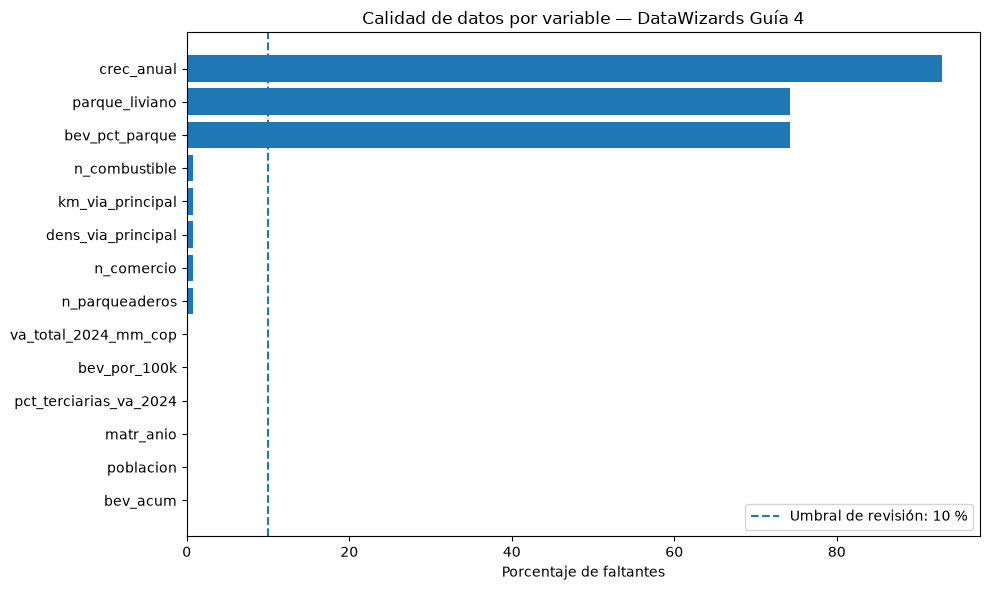

In [5]:
campos = [c for c in ["poblacion", "bev_acum", "matr_anio", "crec_anual", "bev_por_100k", "parque_liviano", "bev_pct_parque", "km_via_principal", "dens_via_principal", "n_combustible", "n_comercio", "n_parqueaderos", "va_total_2024_mm_cop", "pct_terciarias_va_2024"] if c in integrada]
calidad = pd.DataFrame({
    "variable": campos,
    "filas": [len(integrada)]*len(campos),
    "nulos": [int(integrada[c].isna().sum()) for c in campos],
    "pct_nulos": [round(100*integrada[c].isna().mean(),2) for c in campos],
    "valores_distintos_no_nulos": [int(integrada[c].nunique(dropna=True)) for c in campos]
}).sort_values("pct_nulos", ascending=False)
calidad["revisar_supera_10pct"] = calidad.pct_nulos > 10
calidad.to_csv(TABLES / "calidad_integrada_por_variable.csv", index=False, encoding="utf-8-sig")
display(calidad)
plt.figure(figsize=(10,6))
plt.barh(calidad.variable[::-1], calidad.pct_nulos[::-1])
plt.axvline(10, linestyle="--", label="Umbral de revisión: 10 %")
plt.xlabel("Porcentaje de faltantes")
plt.title("Calidad de datos por variable — DataWizards Guía 4")
plt.legend(); plt.tight_layout()
plt.savefig(FIGURES / "guia4_faltantes_por_variable.png", dpi=160, bbox_inches="tight")
plt.show()


## 5. Comprensión económica: distribución y contraste exploratorio
Se describen magnitudes económicas y su distribución. Las correlaciones con BEV son **asociaciones**, no efectos causales. Las variables económicas nominales favorecen municipios grandes; los indicadores per cápita deben examinarse junto con tamaño de población y año de referencia.

,count,mean,std,min,5%,25%,50%,75%,95%,99%,max
va_total_2024_mm_cop,1122.0,1.382330e+03,1.208314e+04,1.665261e+00,4.600631e+01,1.317330e+02,2.747560e+02,6.242199e+02,3.988066e+03,1.283245e+04,3.801981e+05
pct_terciarias_va_2024,1122.0,5.464770e+01,1.936929e+01,3.686846e+00,2.108639e+01,4.108802e+01,5.486385e+01,6.921678e+01,8.692063e+01,9.303227e+01,9.708937e+01
va_2024_por_habitante_poblacion_base_cop,1122.0,2.561124e+07,2.559923e+07,2.827725e+06,7.752942e+06,1.359325e+07,1.972795e+07,2.912833e+07,5.880492e+07,1.295125e+08,4.096538e+08
bev_acum,1123.0,5.964470e+01,1.124795e+03,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.700000e+01,5.685800e+02,3.595200e+04
bev_por_100k,1122.0,1.158957e+01,8.459395e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,2.215011e+01,2.954471e+02,1.800053e+03
dens_via_principal,1114.0,1.121377e-01,1.757194e-01,0.000000e+00,0.000000e+00,0.000000e+00,5.842322e-02,1.480766e-01,4.026165e-01,8.851608e-01,2.143606e+00


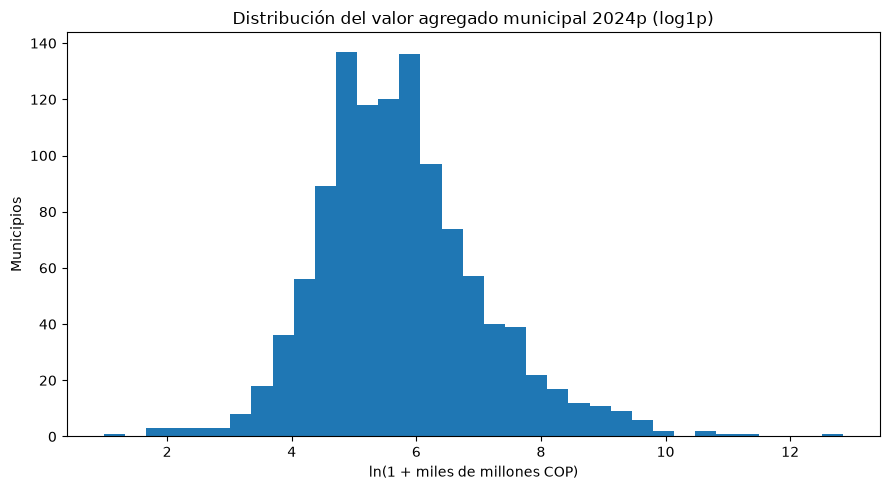

,va_total_2024_mm_cop,pct_terciarias_va_2024,va_2024_por_habitante_poblacion_base_cop,bev_acum,bev_por_100k,dens_via_principal
va_total_2024_mm_cop,1.000,-0.152,0.422,0.494,0.487,0.414
pct_terciarias_va_2024,-0.152,1.000,-0.599,0.157,0.150,0.033
va_2024_por_habitante_poblacion_base_cop,0.422,-0.599,1.000,0.184,0.186,0.253
bev_acum,0.494,0.157,0.184,1.000,0.999,0.382
bev_por_100k,0.487,0.150,0.186,0.999,1.000,0.380
dens_via_principal,0.414,0.033,0.253,0.382,0.380,1.000


In [6]:
variables_num = [c for c in ["va_total_2024_mm_cop","pct_terciarias_va_2024","va_2024_por_habitante_poblacion_base_cop","bev_acum","bev_por_100k","dens_via_principal"] if c in integrada]
resumen = integrada[variables_num].describe(percentiles=[.05,.25,.5,.75,.95,.99]).T
resumen.to_csv(TABLES / "estadisticas_integradas_guia4.csv", encoding="utf-8-sig")
display(resumen)
if "va_total_2024_mm_cop" in integrada:
    fig, ax = plt.subplots(figsize=(9,5))
    datos = integrada["va_total_2024_mm_cop"].dropna()
    ax.hist(np.log1p(datos.clip(lower=0)),bins=35)
    ax.set(title="Distribución del valor agregado municipal 2024p (log1p)",xlabel="ln(1 + miles de millones COP)",ylabel="Municipios")
    fig.tight_layout(); fig.savefig(FIGURES / "guia4_distribucion_va_2024.png",dpi=160);plt.show()
if len(variables_num)>1:
    correlaciones = integrada[variables_num].corr(method="spearman", min_periods=30)
    correlaciones.to_csv(TABLES / "correlaciones_spearman_integradas.csv",encoding="utf-8-sig")
    display(correlaciones.round(3))


## 6. Inventario preliminar de CárgaME (sin asumir disponibilidad operativa)
Se extrae una tabla por estación del JSON suministrado por Jairo, **sin mezclar número de estaciones con conectores ni inferir potencia de carga DC**. `Estado=Activo` es una etiqueta reportada, no verificación de funcionamiento, disponibilidad ni acceso público. Los filtros definitivos de carga rápida requieren validar conectores, potencia, ubicación real y restricciones de acceso.

In [7]:
f_json = RAW / "infraestructura_carga" / "estaciones_cargame.json"
if f_json.exists():
    estaciones = json.loads(f_json.read_text(encoding="utf-8-sig"))
    if isinstance(estaciones,dict):
        estaciones = next((v for v in estaciones.values() if isinstance(v,list)), [])
    def sub(obj, *keys):
        for k in keys:
            obj = obj.get(k, {}) if isinstance(obj,dict) else {}
        return obj if obj != {} else None
    filas=[]
    for e in estaciones:
        if not isinstance(e,dict): continue
        id_mun = sub(e,"Municipio","Id")
        cod = str(id_mun).split(".")[0].zfill(5) if id_mun is not None else None
        filas.append({
            "id_estacion":e.get("Id"), "nombre":e.get("Nombre"),
            "divipola_reportado":cod,
            "municipio_reportado":sub(e,"Municipio","NombreMunicipio"),
            "departamento_reportado":sub(e,"Departamento","NombreDepartamento"),
            "operador":sub(e,"Operador","Nombreempresa"),
            "direccion":e.get("Direccion"),"estado_reportado":e.get("Estado"),
            "acceso_texto":sub(e,"Tipoestacion","Acceso"),
            "puntos_carga_reportados":sub(e,"Tipoestacion","Puntoscarga"),
            "potencia_max_reportada":e.get("PotenciaMax"),
            "observacion":e.get("Observacion")
        })
    cargame = pd.DataFrame(filas)
    cargame.to_csv(PROCESSED / "cargame" / "estaciones_inventario_preliminar.csv",index=False,encoding="utf-8-sig")
    print("Estaciones JSON:",len(cargame),"| IDs repetidos:",cargame.id_estacion.duplicated().sum())
    print("Municipios sin código:",cargame.divipola_reportado.isna().sum())
    display(cargame.head(4))
    print("ADVERTENCIA: no agregar estos conteos al ranking como cargadores DC públicos verificados.")
else:
    print("No está el JSON de CárgaME; se omite esta sección.")


Estaciones JSON: 214 | IDs repetidos: 0
Municipios sin código: 0


,id_estacion,nombre,divipola_reportado,municipio_reportado,departamento_reportado,operador,direccion,estado_reportado,acceso_texto,puntos_carga_reportados,potencia_max_reportada,observacion
0,C5B2C958-AB6A-F111-A079-8187F68C9E81,Estación Cariongo,54001,CUCUTA,NORTE DE SANTANDER,CENTRALES ELECTRICAS DEL NORTE DE SANTANDER S....,Carrera 5 con calle 9 esquina centro frente a ...,"{'Id': 1, 'NombreEstado': 'Activo'}",En la Playstore descargar e instalar la App Ce...,1,44.0,Pueden conocer la tarifa de parquedaero del Ho...
1,63B2466C-0B30-EF11-9B07-005056BD7421,Estación Ocaña,54001,CUCUTA,NORTE DE SANTANDER,CENTRALES ELECTRICAS DEL NORTE DE SANTANDER S....,"Calle 7, Av. Francisco Fernández de Contreras ...","{'Id': 1, 'NombreEstado': 'Activo'}",En la Playstore descargar e instalar la App Ce...,1,50.0,Los usuarios de vehículos eléctricos o híbrido...
2,529647BD-E824-ED11-9B91-005056BD1A8D,Estación Unicentro,54001,CUCUTA,NORTE DE SANTANDER,CENTRALES ELECTRICAS DEL NORTE DE SANTANDER S....,"Avenida 4 # 2b Norte 81, 12N","{'Id': 1, 'NombreEstado': 'Activo'}",En la Playstore descargar e instalar la App Ce...,1,22.0,Los usuarios de vehículos eléctricos o híbrido...
3,78BE5448-E838-ED11-9B91-005056BD1A8D,Estación Ventura Plaza,54001,CUCUTA,NORTE DE SANTANDER,CENTRALES ELECTRICAS DEL NORTE DE SANTANDER S....,"Calle 10 y 11 con Diagonal Santander, Quinta v...","{'Id': 1, 'NombreEstado': 'Activo'}",En la Playstore descargar e instalar la App Ce...,1,50.0,Los usuarios de vehículos eléctricos o híbrido...


ADVERTENCIA: no agregar estos conteos al ranking como cargadores DC públicos verificados.


## 7. Bitácora metodológica y resumen reproducible
Las decisiones sobre datos faltantes o accesibilidad deben basarse en fuentes y documentación de Erika; el notebook no altera su EDA ni presume que las variables OSM sean indicadores definitivos de acceso a electrolineras. El valor agregado económico es una variable contextual, no demanda observada.

In [8]:
bitacora = pd.DataFrame([
    {"etapa":"EDA base", "decision":"EDA_ACC seleccionada por cinco variables adicionales y 0 diferencias en 12 variables originales", "justificacion":"Validación exacta por DIVIPOLA; mantener ambos originales"},
    {"etapa":"DANE", "decision":"Conservar solo DIVIPOLA de cinco dígitos; excluir notas finales", "justificacion":"Evitar que metadatos se contabilicen como municipios"},
    {"etapa":"DANE", "decision":"Conservar montos en miles de millones COP corrientes; 2024 provisional", "justificacion":"Mantener unidad, fecha y carácter provisional"},
    {"etapa":"Conciliación", "decision":"Cruce izquierda con validación uno-a-uno", "justificacion":"No perder ni multiplicar registros de la base de 1.123 municipios"},
    {"etapa":"Faltantes", "decision":"No imputar automáticamente VA, crecimiento ni parque liviano", "justificacion":"Analizar ausencia y cobertura antes de cualquier imputación"},
    {"etapa":"Electromovilidad", "decision":"No interpretar híbridos no clasificados como PHEV, ni motos/ciclomotores como demanda DC de pasajeros", "justificacion":"Evitar sobreestimación de demanda de carga rápida"},
    {"etapa":"CárgaME", "decision":"Conservar inventario preliminar sin declarar estaciones DC públicas operativas", "justificacion":"Requiere validación de conectores, potencia, acceso y ubicación"},
    {"etapa":"Contexto económico", "decision":"VA nominal 2024p usado como contexto, no como demanda observada", "justificacion":"Años de referencia distintos; correlación no implica causalidad"},
])
bitacora.to_csv(TABLES / "bitacora_integracion_guia4.csv",index=False,encoding="utf-8-sig")

texto = f"""# Resumen automático de integración · Guía 4

- EDA_ACC: {len(acc)} municipios y {len(acc.columns)} variables, con 0 diferencias en las variables comunes al EDA.
- DANE Cuadro 15 (2024p): {len(dane)} registros municipales válidos de {len(original)} filas leídas; {len(filas_descartadas)} filas no municipales excluidas.
- Coincidencias DANE–EDA_ACC: {(integrada['_merge']=='both').sum()}; sin valor agregado: {len(solo_eda)}; solo en DANE: {len(solo_dane)}.
- La tabla integrada conserva {len(integrada)} municipios.
- Variables con más del 10 % de faltantes: {', '.join(calidad.loc[calidad.pct_nulos.gt(10), 'variable']) or 'ninguna'}.
- La fuente DANE está en miles de millones de COP corrientes, 2024 provisional; cualquier indicador normalizado por población exige verificar el año poblacional de la base de Erika.
- CárgaME se conserva como inventario preliminar y no se considera infraestructura DC pública operativa validada.

## Pendientes antes de un ranking
1. Verificar año de población, compatibilidad de fechas y restricciones de fuentes.
2. Investigar diferencias de DIVIPOLA, incluyendo cambios territoriales.
3. Validar criterios BEV de pasajeros, cobertura de parque liviano y ausencia de crecimiento.
4. Auditar conectores DC, potencia, acceso público, duplicados y geoposiciones en CárgaME.
5. Justificar métricas de accesibilidad, normalización y análisis de sensibilidad con expertos.
"""
(TABLES / "resumen_integracion_guia4.md").write_text(texto,encoding="utf-8")
print(texto)
print("Archivos generados en:", TABLES, PROCESSED / "integracion", PROCESSED / "dane", FIGURES)


# Resumen automático de integración · Guía 4

- EDA_ACC: 1123 municipios y 17 variables, con 0 diferencias en las variables comunes al EDA.
- DANE Cuadro 15 (2024p): 1122 registros municipales válidos de 1131 filas leídas; 9 filas no municipales excluidas.
- Coincidencias DANE–EDA_ACC: 1122; sin valor agregado: 1; solo en DANE: 0.
- La tabla integrada conserva 1123 municipios.
- Variables con más del 10 % de faltantes: crec_anual, parque_liviano, bev_pct_parque.
- La fuente DANE está en miles de millones de COP corrientes, 2024 provisional; cualquier indicador normalizado por población exige verificar el año poblacional de la base de Erika.
- CárgaME se conserva como inventario preliminar y no se considera infraestructura DC pública operativa validada.

## Pendientes antes de un ranking
1. Verificar año de población, compatibilidad de fechas y restricciones de fuentes.
2. Investigar diferencias de DIVIPOLA, incluyendo cambios territoriales.
3. Validar criterios BEV de pasajeros, cobert

### Entregables principales
- `data/processed/dane/valor_agregado_municipal_2024.csv`
- `data/processed/integracion/indicadores_municipales_con_dane_2024.csv`
- `data/processed/cargame/estaciones_inventario_preliminar.csv`
- `reports/tables/guia4/`: conciliación DIVIPOLA, limpieza, calidad, correlaciones y bitácora.
- `reports/figures/`: faltantes y distribución económica.

**Criterios de Guía 4:** calidad (10 %), limpieza (45 %), comprensión (45 %). Este notebook aporta evidencias reproducibles, pero la validación final de infraestructura DC y del diseño del índice de decisión permanece pendiente.

In [10]:

import pandas as pd
from pathlib import Path
from scipy.stats import spearmanr

raiz = Path.cwd()
if not (raiz / "data").exists():
    raiz = raiz.parent

ruta = raiz / "data/processed/integracion/indicadores_municipales_con_dane_2024.csv"
df = pd.read_csv(ruta, dtype={"divipola": str})

print("=== AUDITORÍA DE BEV ===")
print("Municipios totales:", len(df))
print("Municipios BEV = 0:", (df["bev_acum"] == 0).sum())
print("Municipios BEV > 0:", (df["bev_acum"] > 0).sum())
print("BEV acumulados:", df["bev_acum"].sum())

pares = [
    ("bev_acum", "bev_por_100k"),
    ("va_total_2024_mm_cop", "bev_acum"),
    ("va_total_2024_mm_cop", "bev_por_100k"),
    ("dens_via_principal", "bev_acum"),
    ("dens_via_principal", "bev_por_100k"),
]

resultados = []

print("\n=== COMPARACIÓN DE CORRELACIONES ===")

for x, y in pares:
    todos = df[[x, y]].dropna()
    positivos = df.loc[df["bev_acum"] > 0, [x, y]].dropna()

    def calcular(data):
        if len(data) < 3:
            return float("nan")
        if data[x].nunique() < 2 or data[y].nunique() < 2:
            return float("nan")
        return spearmanr(data[x], data[y]).statistic

    rho_todos = calcular(todos)
    rho_positivos = calcular(positivos)

    resultados.append({
        "variable_x": x,
        "variable_y": y,
        "n_todos": len(todos),
        "rho_todos": rho_todos,
        "n_bev_positivos": len(positivos),
        "rho_bev_positivos": rho_positivos
    })

resumen = pd.DataFrame(resultados)
print(resumen.to_string(index=False))

# Guardar evidencia para la Guía 4
salida = raiz / "reports/tables/guia4/auditoria_correlaciones_bev.csv"
salida.parent.mkdir(parents=True, exist_ok=True)
resumen.to_csv(salida, index=False, encoding="utf-8-sig")

print("\nEvidencia guardada en:", salida)

# Auditar las clases originales de RUNT
archivos = sorted(
    (raiz / "data/raw/runt_andi").glob("*20261114.csv")
)

if archivos:
    runt = pd.read_csv(archivos[0], dtype=str)
    runt.columns = runt.columns.str.strip()

    electricos = runt.loc[
        runt["COMBUSTIBLE"].str.strip().str.upper().eq("ELECTRICO")
    ].copy()

    electricos["cantidad_num"] = pd.to_numeric(
        electricos["CANTIDAD"]
        .fillna("0")
        .str.replace(",", "", regex=False),
        errors="coerce"
    )

    print("\n=== RUNT ELÉCTRICOS POR CLASE ===")
    print(
        electricos.groupby("CLASE")["cantidad_num"]
        .sum().sort_values(ascending=False)
        .to_string()
    )

    clases_pasajeros = ["AUTOMOVIL", "CAMIONETA", "CAMPERO"]
    total_pasajeros = electricos.loc[
        electricos["CLASE"].str.strip().str.upper()
        .isin(clases_pasajeros),
        "cantidad_num"
    ].sum()

    print("\nBEV pasajeros:", total_pasajeros)
    print("BEV todas las clases:", electricos["cantidad_num"].sum())
    print("BEV base integrada:", df["bev_acum"].sum())
else:
    print("\nNo se encontró el RUNT del 14/11.")


=== AUDITORÍA DE BEV ===
Municipios totales: 1123
Municipios BEV = 0: 969
Municipios BEV > 0: 154
BEV acumulados: 66981.0

=== COMPARACIÓN DE CORRELACIONES ===
          variable_x   variable_y  n_todos  rho_todos  n_bev_positivos  rho_bev_positivos
            bev_acum bev_por_100k     1122   0.998934              154           0.851484
va_total_2024_mm_cop     bev_acum     1122   0.493756              154           0.471355
va_total_2024_mm_cop bev_por_100k     1122   0.487246              154           0.042181
  dens_via_principal     bev_acum     1114   0.382264              152           0.441269
  dens_via_principal bev_por_100k     1114   0.380092              152           0.321797

Evidencia guardada en: E:\MIAD\DATAWIZARDS_Proyecto\reports\tables\guia4\auditoria_correlaciones_bev.csv

=== RUNT ELÉCTRICOS POR CLASE ===
CLASE
CAMIONETA       48079
AUTOMOVIL       18653
CICLOMOTOR      15621
BUS              1785
CUADRICICLO      1602
MOTOCICLETA      1540
MOTOCARRO         991

In [11]:
import pandas as pd
from pathlib import Path

raiz = Path.cwd()
if not (raiz / "data").exists():
    raiz = raiz.parent

ruta = raiz / "data/processed/cargame/estaciones_inventario_preliminar.csv"
cargame = pd.read_csv(ruta)

print("=== INVENTARIO CÁRGAME ===")
print("Estaciones:", len(cargame))
print("\nCOLUMNAS:")
print(cargame.columns.tolist())

print("\nPRIMEROS REGISTROS:")
print(cargame.head(3).to_string(index=False))

print("\nFALTANTES:")
print(cargame.isna().sum().sort_values(ascending=False).to_string())

=== INVENTARIO CÁRGAME ===
Estaciones: 214

COLUMNAS:
['id_estacion', 'nombre', 'divipola_reportado', 'municipio_reportado', 'departamento_reportado', 'operador', 'direccion', 'estado_reportado', 'acceso_texto', 'puntos_carga_reportados', 'potencia_max_reportada', 'observacion']

PRIMEROS REGISTROS:
                         id_estacion             nombre  divipola_reportado municipio_reportado departamento_reportado                                             operador                                                         direccion                    estado_reportado                                                                                acceso_texto  puntos_carga_reportados  potencia_max_reportada                                                                                                                                                                                                                                                                         observacion
C5B2C958

In [12]:

import json
from pathlib import Path
import pandas as pd

raiz = Path.cwd()
if not (raiz / "data").exists():
    raiz = raiz.parent

ruta = raiz / "data/raw/infraestructura_carga/estaciones_cargame.json"

with open(ruta, encoding="utf-8-sig") as f:
    datos = json.load(f)

print("TIPO DE ESTRUCTURA:", type(datos).__name__)

if isinstance(datos, dict):
    print("CLAVES PRINCIPALES:", list(datos.keys()))
    for clave, valor in datos.items():
        if isinstance(valor, list):
            print("LISTA ENCONTRADA:", clave, len(valor))
            datos = valor
            break

if isinstance(datos, list) and datos:
    print("\nTOTAL REGISTROS:", len(datos))
    print("\nCAMPOS DE UNA ESTACIÓN:")
    print(list(datos[0].keys()))

    print("\nCONECTORES DE LAS TRES PRIMERAS ESTACIONES:")
    for estacion in datos[:3]:
        print("\nEstación:", estacion.get("Nombre"))
        print("Conectores:", estacion.get("Conectores"))
        print("Acceso:", estacion.get("Acceso"))
        print("Potencia:", estacion.get("PotenciaMax"))
else:
    print("Es necesario revisar la estructura interna del JSON.")


TIPO DE ESTRUCTURA: list

TOTAL REGISTROS: 214

CAMPOS DE UNA ESTACIÓN:
['Id', 'Operador', 'Nombre', 'Direccion', 'Departamento', 'Municipio', 'Ubicacion', 'Tipoestacion', 'Parqueadero', 'Horario', 'Latitud', 'Longitud', 'Altitud', 'PuntoWkb', 'Fechacreacion', 'Estado', 'Observacion', 'Files', 'Acceso', 'Puntoscarga', 'Conectores', 'PotenciaMax', 'Cobros', 'Precios']

CONECTORES DE LAS TRES PRIMERAS ESTACIONES:

Estación: Estación Cariongo
Conectores: {'Tipo 1 - SAE J1772': 1, 'Tipo 2 - IEC 62196': 1}
Acceso: En la Playstore descargar e instalar la App CensEV para poder recargar y pagar el servicio.
Potencia: 44

Estación: Estación Ocaña
Conectores: {'CCS Combo 1': 1, 'CHAdeMO': 1, 'Tipo 2 - IEC 62196': 1}
Acceso: En la Playstore descargar e instalar la App CensEV para poder recargar y pagar el servicio.
Potencia: 50

Estación: Estación Unicentro
Conectores: {'Tipo 1 - SAE J1772': 1, 'Tipo 2 - IEC 62196': 1}
Acceso: En la Playstore descargar e instalar la App CensEV para poder recargar

In [13]:

import json
import re
import unicodedata
from pathlib import Path
import pandas as pd

raiz = Path.cwd()
if not (raiz / "data").exists():
    raiz = raiz.parent

with open(
    raiz / "data/raw/infraestructura_carga/estaciones_cargame.json",
    encoding="utf-8-sig"
) as archivo:
    estaciones = json.load(archivo)

def normalizar(texto):
    texto = unicodedata.normalize("NFKD", str(texto or ""))
    texto = "".join(c for c in texto if not unicodedata.combining(c))
    return texto.upper().strip()

def extraer_estado(valor):
    if isinstance(valor, dict):
        return valor.get("NombreEstado", "")
    return str(valor or "")

def revisar_estacion(e):
    conectores = e.get("Conectores") or {}
    if not isinstance(conectores, dict):
        conectores = {}

    nombres = [normalizar(k) for k in conectores]

    # CCS y CHAdeMO son conectores de carga DC.
    # No clasificar Tipo 2 por sí solo como DC.
    tiene_dc = any(
        "CCS" in c or "CHADEMO" in c or "GB/T DC" in c
        for c in nombres
    )

    tiene_ac = any(
        "J1772" in c
        or "TIPO 2" in c
        or "TYPE 2" in c
        or "MENNEKES" in c
        for c in nombres
    )

    if tiene_dc:
        tipo = "Con evidencia DC"
    elif tiene_ac:
        tipo = "Solo AC identificado"
    else:
        tipo = "Tipo por verificar"

    acceso = normalizar(e.get("Acceso"))
    obs = normalizar(e.get("Observacion"))
    texto_acceso = acceso + " " + obs

    restringido = bool(re.search(
        r"SOLO.*COLABORADOR|USO EXCLUSIVO|"
        r"NO ES DE ACCESO PUBLICO|USO PRIVADO|"
        r"SOLO.*EMPLEAD|ACCESO RESTRINGIDO",
        texto_acceso
    ))

    # La ausencia de restricciones NO prueba acceso público.
    if restringido:
        acceso_clase = "Restricción explícita"
    elif not acceso:
        acceso_clase = "Sin información de acceso"
    else:
        acceso_clase = "Acceso por verificar"

    estado = extraer_estado(e.get("Estado"))

    potencia = pd.to_numeric(
        e.get("PotenciaMax"), errors="coerce"
    )

    ubicacion = e.get("Municipio") or {}
    if isinstance(ubicacion, dict):
        divipola = ubicacion.get("Id")
        municipio = ubicacion.get("Nombre")
    else:
        divipola = None
        municipio = str(ubicacion)

    divipola = (
        str(divipola).zfill(5)
        if divipola is not None else None
    )

    requiere_revision = (
        tipo == "Tipo por verificar"
        or acceso_clase != "Acceso por verificar"
        or pd.isna(potencia)
        or not municipio
    )

    return {
        "id_estacion": e.get("Id"),
        "nombre": e.get("Nombre"),
        "divipola_reportado": divipola,
        "municipio_reportado": municipio,
        "estado_reportado": estado,
        "conectores": json.dumps(conectores, ensure_ascii=False),
        "tipo_conector": tipo,
        "tiene_dc": tiene_dc,
        "tiene_ac": tiene_ac,
        "acceso_clasificado": acceso_clase,
        "potencia_max_reportada_kw": potencia,
        "puntos_carga_reportados": e.get("Puntoscarga"),
        "latitud": e.get("Latitud"),
        "longitud": e.get("Longitud"),
        "direccion": e.get("Direccion"),
        "requiere_revision_datos": requiere_revision
    }

df_carga = pd.DataFrame(
    [revisar_estacion(e) for e in estaciones]
)

# Indicador de evidencia, NO de operación real
df_carga["candidata_dc_sin_restriccion_explicita"] = (
    df_carga["tiene_dc"]
    & df_carga["acceso_clasificado"].eq("Acceso por verificar")
)

print("=== AUDITORÍA CÁRGAME ===")
print("Estaciones:", len(df_carga))
print("IDs duplicados:", df_carga["id_estacion"].duplicated().sum())

print("\nTIPO DE CONECTOR:")
print(df_carga["tipo_conector"].value_counts().to_string())

print("\nACCESO:")
print(df_carga["acceso_clasificado"].value_counts().to_string())

print("\nESTADOS REPORTADOS:")
print(df_carga["estado_reportado"].value_counts().to_string())

print("\nESTACIONES CON EVIDENCIA DC:",
      int(df_carga["tiene_dc"].sum()))

print("DC sin restricción explícita detectada:",
      int(df_carga["candidata_dc_sin_restriccion_explicita"].sum()))

print("Potencia faltante:",
      int(df_carga["potencia_max_reportada_kw"].isna().sum()))

# Guardar evidencia para la Guía 4
destino = raiz / "reports/tables/guia4"
destino.mkdir(parents=True, exist_ok=True)

df_carga.to_csv(
    destino / "auditoria_estaciones_cargame.csv",
    index=False,
    encoding="utf-8-sig"
)

resumen = pd.concat([
    df_carga["tipo_conector"].value_counts()
        .rename_axis("categoria").reset_index(name="cantidad")
        .assign(dimension="Conector"),
    df_carga["acceso_clasificado"].value_counts()
        .rename_axis("categoria").reset_index(name="cantidad")
        .assign(dimension="Acceso")
], ignore_index=True)

resumen.to_csv(
    destino / "resumen_auditoria_cargame.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nReportes guardados en:", destino)


=== AUDITORÍA CÁRGAME ===
Estaciones: 214
IDs duplicados: 0

TIPO DE CONECTOR:
tipo_conector
Con evidencia DC        111
Solo AC identificado    100
Tipo por verificar        3

ACCESO:
acceso_clasificado
Acceso por verificar         187
Sin información de acceso     26
Restricción explícita          1

ESTADOS REPORTADOS:
estado_reportado
Activo    214

ESTACIONES CON EVIDENCIA DC: 111
DC sin restricción explícita detectada: 98
Potencia faltante: 2

Reportes guardados en: E:\MIAD\DATAWIZARDS_Proyecto\reports\tables\guia4


In [14]:

import pandas as pd

print("=== DC POR CLASIFICACIÓN DE ACCESO ===")
print(pd.crosstab(
    df_carga["tipo_conector"],
    df_carga["acceso_clasificado"],
    margins=True
).to_string())

print("\n=== DISTRIBUCIÓN DE POTENCIA EN ESTACIONES DC ===")
dc = df_carga.loc[df_carga["tiene_dc"]].copy()
potencia = dc["potencia_max_reportada_kw"]

print("DC con potencia faltante:", potencia.isna().sum())
print("DC con potencia < 50 kW:", (potencia < 50).sum())
print("DC con potencia >= 50 kW:", (potencia >= 50).sum())
print("Mediana de potencia DC:", potencia.median())

print("\n=== DC NO INCLUIDAS COMO CANDIDATAS ===")
cols = [
    "nombre", "municipio_reportado",
    "acceso_clasificado", "potencia_max_reportada_kw"
]
print(
    dc.loc[
        ~dc["candidata_dc_sin_restriccion_explicita"],
        cols
    ].to_string(index=False)
)

print("\n=== CONECTORES POR VERIFICAR ===")
print(
    df_carga.loc[
        df_carga["tipo_conector"] == "Tipo por verificar",
        ["nombre", "conectores", "potencia_max_reportada_kw"]
    ].to_string(index=False)
)


=== DC POR CLASIFICACIÓN DE ACCESO ===
acceso_clasificado    Acceso por verificar  Restricción explícita  Sin información de acceso  All
tipo_conector                                                                                    
Con evidencia DC                        98                      0                         13  111
Solo AC identificado                    87                      1                         12  100
Tipo por verificar                       2                      0                          1    3
All                                    187                      1                         26  214

=== DISTRIBUCIÓN DE POTENCIA EN ESTACIONES DC ===
DC con potencia faltante: 0
DC con potencia < 50 kW: 52
DC con potencia >= 50 kW: 59
Mediana de potencia DC: 50.0

=== DC NO INCLUIDAS COMO CANDIDATAS ===
                        nombre municipio_reportado        acceso_clasificado  potencia_max_reportada_kw
         Celsia Mercacentro 10                None Sin informac

In [15]:

import re
import pandas as pd

print("=== ESTRUCTURA REAL DEL MUNICIPIO ===")
for e in estaciones[:3]:
    print(e.get("Nombre"), ":", e.get("Municipio"))

print("\n=== CONECTORES GB/T ===")
for e in estaciones:
    conectores = e.get("Conectores") or {}
    if isinstance(conectores, dict):
        if any(
            "GB-T" in str(k).upper()
            or "GB/T" in str(k).upper()
            for k in conectores
        ):
            print(e.get("Nombre"), conectores)

# Corregir clasificación DC en el resultado de auditoría
def reconoce_dc(conectores):
    if not isinstance(conectores, dict):
        return False
    return any(
        re.search(
            r"CCS|CHADEMO|GB[\s/\-]?T\s*DC",
            normalizar(k)
        )
        for k in conectores
    )

df_carga["tiene_dc"] = [
    reconoce_dc(e.get("Conectores") or {})
    for e in estaciones
]

df_carga["tipo_conector"] = [
    "Con evidencia DC" if dc
    else ("Solo AC identificado" if ac else "Tipo por verificar")
    for dc, ac in zip(
        df_carga["tiene_dc"],
        df_carga["tiene_ac"]
    )
]

df_carga["candidata_dc_sin_restriccion_explicita"] = (
    df_carga["tiene_dc"]
    & df_carga["acceso_clasificado"].eq("Acceso por verificar")
)

print("\n=== CLASIFICACIÓN DC CORREGIDA ===")
print(df_carga["tipo_conector"].value_counts())
print(
    "\nDC sin restricción explícita detectada:",
    df_carga["candidata_dc_sin_restriccion_explicita"].sum()
)

print("\n=== DISTRIBUCIÓN DE POTENCIA DC ===")
dc = df_carga[df_carga["tiene_dc"]]
p = dc["potencia_max_reportada_kw"]
print("Potencia >= 50 kW:", (p >= 50).sum())
print("Potencia < 50 kW:", (p < 50).sum())
print("Potencia faltante:", p.isna().sum())

# Actualizar archivo de auditoría
destino = raiz / "reports/tables/guia4/auditoria_estaciones_cargame.csv"
df_carga.to_csv(destino, index=False, encoding="utf-8-sig")


=== ESTRUCTURA REAL DEL MUNICIPIO ===
Estación Cariongo : {'Id': 54001, 'NombreMunicipio': 'CUCUTA'}
Estación Ocaña : {'Id': 54001, 'NombreMunicipio': 'CUCUTA'}
Estación Unicentro : {'Id': 54001, 'NombreMunicipio': 'CUCUTA'}

=== CONECTORES GB/T ===
Fundadores {'Tipo 2 - IEC 62196': 4, 'Tipo 1 - SAE J1772': 2, 'GB-T AC': 2}
Celsia Aeropuerto El Dorado {'Tipo 1 - SAE J1772': 1, 'Tipo 2 - IEC 62196': 1, 'GB-T AC': 1}
Celsia Autosura Rio 10 {'Tipo 1 - SAE J1772': 1, 'Tipo 2 - IEC 62196': 2, 'GB-T AC': 1}
Celsia CC Del Este {'Tipo 1 - SAE J1772': 2, 'Tipo 2 - IEC 62196': 1, 'GB-T AC': 1}
Celsia CC Oviedo {'Tipo 1 - SAE J1772': 1, 'GB-T AC': 1, 'Tipo 2 - IEC 62196': 1}
EDS Autopista Norte {'GB-T DC': 1, 'CCS Combo 1': 1, 'CCS Combo 2': 1}
EDS Av Boyacá {'GB-T DC': 1, 'CCS Combo 1': 1, 'CCS Combo 2': 1}
EDS Báscula {'GB-T DC': 1, 'CCS Combo 1': 1, 'CCS Combo 2': 1}
EDS Cañasgordas {'GB-T DC': 2, 'CCS Combo 1': 2, 'CCS Combo 2': 2}
EDS Centro {'GB-T DC': 1, 'CCS Combo 1': 1, 'CCS Combo 2': 1}

In [16]:

import pandas as pd
import re

def municipio_reportado(e):
    m = e.get("Municipio") or {}
    if not isinstance(m, dict):
        return None, str(m) if m else None

    codigo = m.get("Id")
    nombre = m.get("NombreMunicipio")

    if codigo is not None:
        codigo = str(codigo).zfill(5)

    return codigo, nombre

municipios = [municipio_reportado(e) for e in estaciones]

df_carga["divipola_reportado"] = [m[0] for m in municipios]
df_carga["municipio_reportado"] = [m[1] for m in municipios]

# Casos específicos detectados en la exploración
patrones = {
    "Estación Ocaña": "Revisar: dirección Ocaña, código Cúcuta",
    "EDS Aeropuerto José María Córdova":
        "Revisar: ubicación Rionegro",
    "EDS Sabaneta":
        "Revisar: ubicación Sabaneta"
}

df_carga["alerta_territorial"] = (
    df_carga["nombre"].map(patrones).fillna("")
)

print("=== CALIDAD TERRITORIAL CÁRGAME ===")
print("Estaciones:", len(df_carga))
print("Sin DIVIPOLA:", df_carga["divipola_reportado"].isna().sum())
print("Sin nombre municipal:", df_carga["municipio_reportado"].isna().sum())
print("DIVIPOLA distintos:", df_carga["divipola_reportado"].nunique())

print("\n=== CASOS IDENTIFICADOS PARA REVISIÓN ===")
print(
    df_carga.loc[
        df_carga["alerta_territorial"] != "",
        ["nombre", "divipola_reportado",
         "municipio_reportado", "direccion",
         "alerta_territorial"]
    ].to_string(index=False)
)

# Comprobar concordancia con la base municipal
base = pd.read_csv(
    raiz / "data/processed/integracion/"
           "indicadores_municipales_con_dane_2024.csv",
    dtype={"divipola": str}
)

codigos_base = set(base["divipola"].str.zfill(5))

df_carga["divipola_existe_base"] = (
    df_carga["divipola_reportado"].isin(codigos_base)
)

print("\nEstaciones con DIVIPOLA existente en la base:",
      df_carga["divipola_existe_base"].sum())

print("Estaciones con DIVIPOLA sin correspondencia:",
      (~df_carga["divipola_existe_base"]).sum())

# Guardar la auditoría corregida
salida = raiz / "reports/tables/guia4/auditoria_estaciones_cargame.csv"

df_carga.to_csv(
    salida,
    index=False,
    encoding="utf-8-sig"
)

print("\nArchivo actualizado:", salida)


=== CALIDAD TERRITORIAL CÁRGAME ===
Estaciones: 214
Sin DIVIPOLA: 0
Sin nombre municipal: 0
DIVIPOLA distintos: 40

=== CASOS IDENTIFICADOS PARA REVISIÓN ===
        nombre divipola_reportado municipio_reportado                                                    direccion                      alerta_territorial
Estación Ocaña              54001              CUCUTA Calle 7, Av. Francisco Fernández de Contreras #29 183, Ocaña Revisar: dirección Ocaña, código Cúcuta
  EDS Sabaneta              05001            MEDELLIN            CR 48 - AV LAS VEGAS, entre Calle 72 Sur y 73 Sur             Revisar: ubicación Sabaneta

Estaciones con DIVIPOLA existente en la base: 214
Estaciones con DIVIPOLA sin correspondencia: 0

Archivo actualizado: E:\MIAD\DATAWIZARDS_Proyecto\reports\tables\guia4\auditoria_estaciones_cargame.csv


In [17]:

import pandas as pd
from pathlib import Path

raiz = Path.cwd()
if not (raiz / "data").exists():
    raiz = raiz.parent

base = pd.read_csv(
    raiz / "data/processed/integracion/indicadores_municipales_con_dane_2024.csv",
    dtype={"divipola": str}
)

# 1. Municipios sin accesibilidad
variables_osm = [
    "km_via_principal", "dens_via_principal",
    "n_combustible", "n_comercio", "n_parqueaderos"
]

faltantes = base.loc[
    base[variables_osm].isna().any(axis=1),
    ["divipola", "departamento", "municipio"] + variables_osm
]

print("=== MUNICIPIOS SIN INDICADORES OSM ===")
print(faltantes.to_string(index=False))

# 2. Fuente original de población
archivo = raiz / "data/raw/dane_divipola/PPED-AreaMun-2018-2042_VP.xlsx"
excel = pd.ExcelFile(archivo)

print("\n=== ARCHIVO DANE POBLACIÓN ===")
print("Hojas disponibles:", excel.sheet_names)

for hoja in excel.sheet_names[:3]:
    muestra = pd.read_excel(
        archivo, sheet_name=hoja,
        header=None, nrows=8
    )
    print(f"\nHOJA: {hoja}")
    print(muestra.iloc[:, :8].to_string(index=False, header=False))

# 3. Comparar cobertura territorial
print("\n=== POBLACIÓN INTEGRADA ===")
print("Municipios:", len(base))
print("Valores faltantes:", base["poblacion"].isna().sum())
print("Población total registrada:", base["poblacion"].sum())
print("Año utilizado: pendiente de verificar en la preparación de Erika")


=== MUNICIPIOS SIN INDICADORES OSM ===
divipola                                             departamento          municipio  km_via_principal  dens_via_principal  n_combustible  n_comercio  n_parqueaderos
   17001                                                   Caldas          Manizales               NaN                 NaN            NaN         NaN             NaN
   19364                                                    Cauca            Jambaló               NaN                 NaN            NaN         NaN             NaN
   20011                                                    Cesar          Aguachica               NaN                 NaN            NaN         NaN             NaN
   27050                                                    Chocó             Atrato               NaN                 NaN            NaN         NaN             NaN
   27810                                                    Chocó Unión Panamericana               NaN                 NaN         